<center>
  <h1> <strong> Canais Convolucionais no Max Pooling </strong> </h1>
  <h3> U-Net(D2): grafeno </h3>
  <b>Júlia Guedes A. dos Santos & Yasmin B. Shimizu</b>
</center>
 
 
<p style="text-align: center;">
  Parte do Trabalho de Conclusão de Curso <b>Redes neurais clássicas e fuzzy para segmentação de imagens de microscopia eletrônica: desempenho e impactos socioambientais</b>, desenvolvido na Ilum Escola de Ciência do Centro Nacional de Pesquisa em Energia e Materiais (CNPEM) para obtenção do título de Bacharel em Ciência e Tecnologia.
</p>
 
<center>
  <img src="https://github.com/yasminbshimizu/FP-UNet_TEM/blob/main/imagens_README/logos_ilumcnpem.png?raw=true" width="1000"/>
</center>

### **Importação de bibliotecas**

In [12]:
import torch 
import pickle
import io
import os

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.colors import to_rgb
import numpy as np
from sklearn.model_selection import train_test_split

from skimage.metrics import peak_signal_noise_ratio
from skimage.metrics import structural_similarity

import gc

In [13]:
import psutil

memoria = psutil.virtual_memory()

print(f"RAM total: {memoria.total / 1024**3:.2f} GB")
print(f"RAM disponível: {memoria.available / 1024**3:.2f} GB")
print(f"RAM utilizada: {memoria.percent}%")

RAM total: 15.68 GB
RAM disponível: 1.73 GB
RAM utilizada: 89.0%


### **Parâmetros do plot**

In [14]:
plt.rcParams.update({
    # "text.usetex": True,           
    "font.size": 12,                
    "axes.labelsize": 14,          
    "axes.titlesize": 16,
    "xtick.labelsize": 12,          
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "figure.titlesize": 18,
    "figure.dpi": 300,              
    "savefig.dpi": 300              
})

In [15]:
diretorio = "unetD2_final_mos2"

In [16]:
os.makedirs(f"Imagens_interpretabilidade/{diretorio}", exist_ok=True)

In [17]:
import torch.nn.functional as F
def restore_size(x, size):
    x = torch.tensor(x, dtype=torch.float32)

    # Redimensiona as duas últimas dimensões
    x = F.interpolate(
        x,
        size=size,
        mode="nearest"
    )
    return x.numpy()

### **Carregamento dos dados**

In [18]:
dados_mos2 = np.load(
        "../../Datasets_finais/mos2_test_final.npz"
        )

imagens_mos2 = dados_mos2["image"].astype(np.float32)

del dados_mos2

imagens_teste_mos2 = torch.from_numpy(imagens_mos2)

imagens_teste_mos2 = imagens_teste_mos2[19]

del imagens_mos2

if imagens_teste_mos2.ndim == 3:

    imagens_teste_mos2 = imagens_teste_mos2.unsqueeze(1)

gc.collect()

539

Text(0.5, 1.0, 'Imagem de Amostra - MoS$_2$')

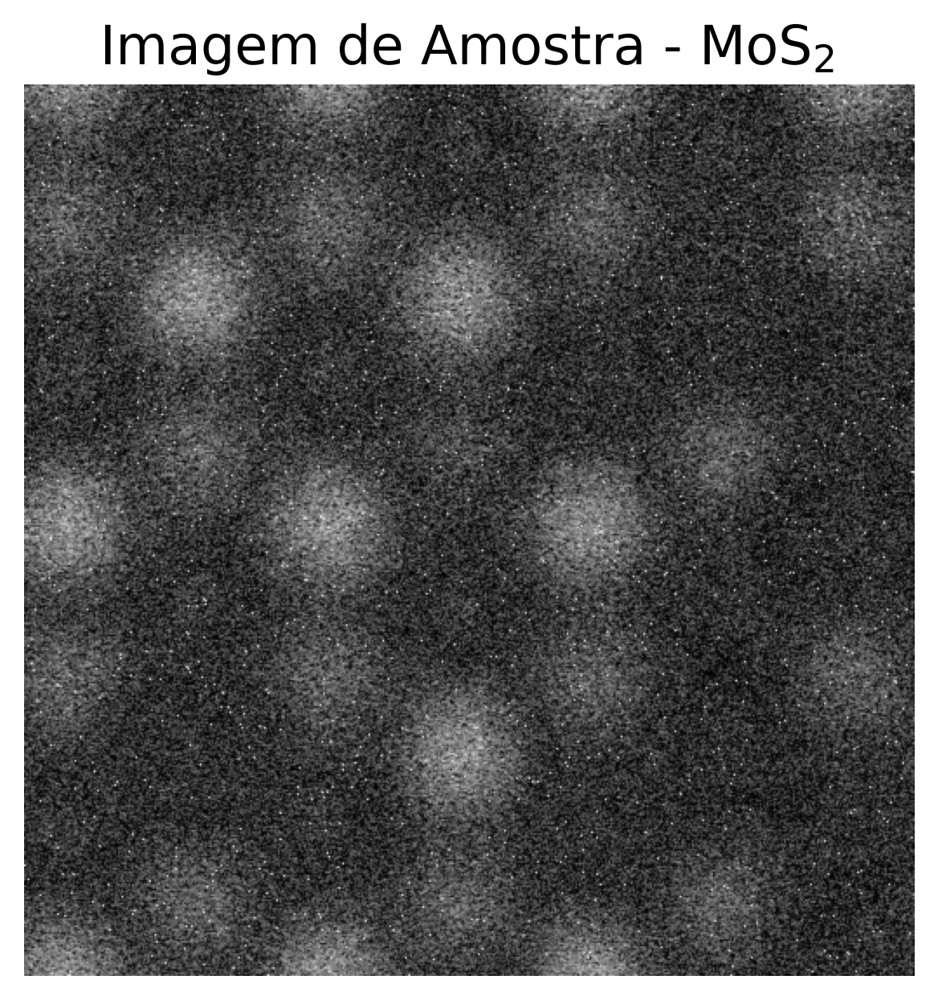

In [19]:
plt.axis("off")
plt.imshow(imagens_teste_mos2[0,:,:][0], cmap='gray', vmin=0, vmax=1)

plt.title(r"Imagem de Amostra - MoS$_2$")

### **U-Net MaxPool MoS2 (Otimizada)**

In [20]:
# Salva a função original
_load_from_bytes_original = torch.storage._load_from_bytes

# Substitui temporariamente por uma versão que força CPU
torch.storage._load_from_bytes = lambda b: torch.load(
    io.BytesIO(b),
    map_location=torch.device("cpu"),
    weights_only=False
)

try:
    with open("../3_Otimização-de-Hiperparâmetros/3_3_Redes-Treinadas/3_3_2_mos2/U_Net_MaxPool_mos2_dados_completos.pkl", "rb") as modelo:
        UNet_mos2_otimizada = pickle.load(modelo)
finally:
    # Restaura a função original
    torch.storage._load_from_bytes = _load_from_bytes_original

UNet_mos2_otimizada = UNet_mos2_otimizada.to("cpu")
UNet_mos2_otimizada.eval()

UNet_MulticlasseD2(
  (down1): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(1, 16, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
      (3): Conv2d(16, 16, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU6(inplace=True)
    )
  )
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (down2): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(16, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_ru

### Max Pooling 1

In [21]:
convolucao1 = UNet_mos2_otimizada.down1(
    imagens_teste_mos2
)

UNet_mos2_otimizada.pool1.return_indices = True
teste_conv1, indices_max1 = UNet_mos2_otimizada.pool1(convolucao1)

imagens_conv1 = convolucao1.detach().cpu().numpy()
imagens_pool1 = teste_conv1.detach().cpu().numpy()

B, C, H, W = convolucao1.shape
indices_pool1 = torch.zeros_like(convolucao1)
rows = indices_max1.long() // W
cols = indices_max1.long() % W
b = torch.arange(B, device=indices_max1.device)[:, None, None, None]
c = torch.arange(C, device=indices_max1.device)[None, :, None, None]
indices_pool1[b, c, rows, cols] = 1
conjuntos1 = indices_pool1.detach().cpu().numpy()

In [22]:
print("MAX POOLING 1 \n")

i = 0  # Única imagem

crms_conv1 = np.zeros((1, 16))
crms_MP1 = np.zeros((1, 16))
psnr1 = np.zeros((1, 16))
ssim1 = np.zeros((1, 16))

pool1_rsz = restore_size(imagens_pool1, (512, 512))

for c in range(16):

    crms_conv1[i, c] = np.std(
        imagens_conv1[i, c],
        correction=0
    )

    crms_MP1[i, c] = np.std(
        pool1_rsz[i, c],
        correction=0
    )

    psnr1[i, c] = peak_signal_noise_ratio(
        imagens_conv1[i, c],
        pool1_rsz[i, c],
        data_range=6
    )

    ssim1[i, c] = structural_similarity(
        imagens_conv1[i, c],
        pool1_rsz[i, c],
        data_range=6
    )

print("Imagem ", 0)
print("Crms Médio (conv): ", round(np.mean(crms_conv1[i]), 4))
print("Crms Médio (MP): ", round(np.mean(crms_MP1[i]), 4))
print("PSNR Médio: ", round(np.mean(psnr1[i]), 4))
print("SSIM Médio: ", round(np.mean(ssim1[i]), 4))
print(" ")


MAX POOLING 1 

Imagem  0
Crms Médio (conv):  0.381
Crms Médio (MP):  0.4473
PSNR Médio:  28.6009
SSIM Médio:  0.693
 


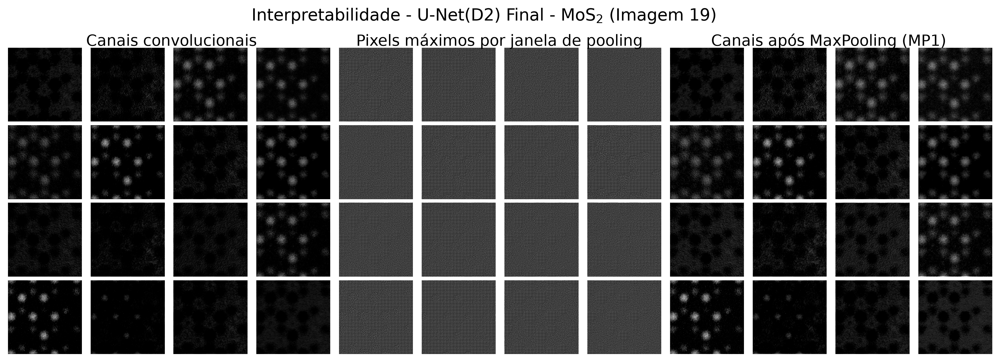

In [23]:
j = 0

fig, axes = plt.subplots(
    4, 12,
    figsize=(16, 5)
)

for i in range(16):

    linha = i // 4
    coluna = i % 4

    # Canais convolucionais
    axes[linha, coluna].imshow(
        imagens_conv1[j, i],
        cmap="gray",
        vmin=0,
        vmax=6
    )
    axes[linha, coluna].axis("off")

    # Pixel Máximos
    axes[linha, coluna + 4].imshow(
        conjuntos1[j, i],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[linha, coluna + 4].axis("off")

    # Saída após FuzzyPooling
    axes[linha, coluna + 8].imshow(
        imagens_pool1[j, i],
        cmap="gray",
        vmin=0,
        vmax=6
    )
    axes[linha, coluna + 8].axis("off")

fig.suptitle(
    r"Interpretabilidade - U-Net(D2) Final - MoS$_2$ (Imagem 19)",
    fontsize=15
)

fig.text(
    0.255, 0.885,
    "Canais convolucionais",
    ha="center",
    fontsize=14,
)

fig.text(
    0.512, 0.885,
    "Pixels máximos por janela de pooling",
    ha="center",
    fontsize=14,
)

fig.text(
    0.77, 0.885,
    "Canais após MaxPooling (MP1)",
    ha="center",
    fontsize=14,
)

plt.subplots_adjust(
    wspace=0.05,
    hspace=0.05,
    top=0.88
)

plt.savefig(
    f"Imagens_interpretabilidade/{diretorio}/MP1_mos2_{diretorio}.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

### Max Pooling 2

In [24]:
convolucao2 = UNet_mos2_otimizada.down2(teste_conv1)

UNet_mos2_otimizada.pool2.return_indices = True
teste_conv2, indices_max2 = UNet_mos2_otimizada.pool2(convolucao2)

imagens_conv2 = convolucao2.detach().cpu().numpy()
imagens_pool2 = teste_conv2.detach().cpu().numpy()

B, C, H, W = convolucao2.shape
indices_pool2 = torch.zeros_like(convolucao2)
rows = indices_max2.long() // W
cols = indices_max2.long() % W
b = torch.arange(B, device=indices_max2.device)[:, None, None, None]
c = torch.arange(C, device=indices_max2.device)[None, :, None, None]
indices_pool2[b, c, rows, cols] = 1
conjuntos2 = indices_pool2.detach().cpu().numpy()

In [25]:
print("MAX POOLING 2 \n")

i = 0  # Única imagem

crms_conv2 = np.zeros((1, 32))
crms_MP2 = np.zeros((1, 32))
psnr2 = np.zeros((1, 32))
ssim2 = np.zeros((1, 32))

pool2_rsz = restore_size(imagens_pool2, (256, 256))

for c in range(32):

    crms_conv2[i, c] = np.std(
        imagens_conv2[i, c],
        correction=0
    )

    crms_MP2[i, c] = np.std(
        pool2_rsz[i, c],
        correction=0
    )

    psnr2[i, c] = peak_signal_noise_ratio(
        imagens_conv2[i, c],
        pool2_rsz[i, c],
        data_range=6
    )

    ssim2[i, c] = structural_similarity(
        imagens_conv2[i, c],
        pool2_rsz[i, c],
        data_range=6
    )

print("Imagem ", 0)
print("Crms Médio (conv): ", round(np.mean(crms_conv2[i]), 4))
print("Crms Médio (MP): ", round(np.mean(crms_MP2[i]), 4))
print("PSNR Médio: ", round(np.mean(psnr2[i]), 4))
print("SSIM Médio: ", round(np.mean(ssim2[i]), 4))
print(" ")

MAX POOLING 2 

Imagem  0
Crms Médio (conv):  0.4136
Crms Médio (MP):  0.4615
PSNR Médio:  30.9082
SSIM Médio:  0.8645
 


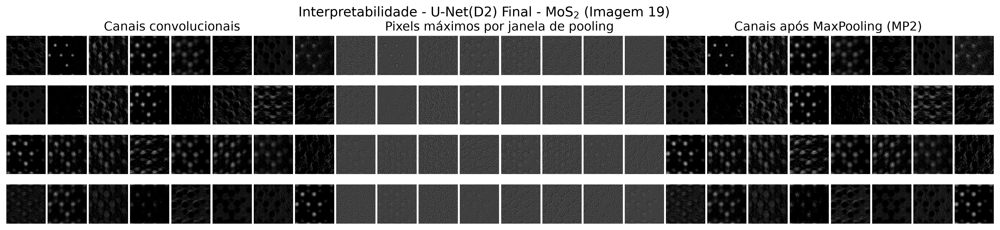

In [26]:
j = 0

fig, axes = plt.subplots(
    4, 24,
    figsize=(20, 4)
)

for i in range(32):

    linha = i // 8
    coluna = i % 8

    # Canais convolucionais
    axes[linha, coluna].imshow(
        imagens_conv2[j, i],
        cmap="gray",
        vmin=0,
        vmax=6
    )
    axes[linha, coluna].axis("off")

     # Pixel Máximo
    axes[linha, coluna + 8].imshow(
        conjuntos2[j, i], cmap="gray", vmin=0, vmax=1
    )
    axes[linha, coluna + 8].axis("off")

    # Saída após MaxPooling
    axes[linha, coluna + 16].imshow(
        imagens_pool2[j, i],
        cmap="gray",
        vmin=0,
        vmax=6
    )
    axes[linha, coluna + 16].axis("off")

fig.suptitle(
    r"Interpretabilidade - U-Net(D2) Final - MoS$_2$ (Imagem 19)",
    fontsize=15
)

fig.text(
    0.255, 0.885,
    "Canais convolucionais",
    ha="center",
    fontsize=14
)

fig.text(
    0.512, 0.885,
    "Pixels máximos por janela de pooling",
    ha="center",
    fontsize=14
)

fig.text(
    0.77, 0.885,
    "Canais após MaxPooling (MP2)",
    ha="center",
    fontsize=14
)

plt.subplots_adjust(
    wspace=0.05,
    hspace=0.05,
    top=0.88
)

plt.savefig(
    f"Imagens_interpretabilidade/{diretorio}/MP2_mos2_{diretorio}.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

### Max Pooling 3

In [27]:
convolucao3 = UNet_mos2_otimizada.down3(teste_conv2)

UNet_mos2_otimizada.pool3.return_indices = True
teste_conv3, indices_max3 = UNet_mos2_otimizada.pool3(convolucao3)

imagens_conv3 = convolucao3.detach().cpu().numpy()
imagens_pool3 = teste_conv3.detach().cpu().numpy()

B, C, H, W = convolucao3.shape
indices_pool3 = torch.zeros_like(convolucao3)
rows = indices_max3.long() // W
cols = indices_max3.long() % W
b = torch.arange(B, device=indices_max3.device)[:, None, None, None]
c = torch.arange(C, device=indices_max3.device)[None, :, None, None]
indices_pool3[b, c, rows, cols] = 1
conjuntos3 = indices_pool3.detach().cpu().numpy()

In [28]:
print("Max POOLING 3 \n")

crms_conv3 = np.zeros((1, 64)) # imagem, canal
crms_MP3 = np.zeros((1, 64))
psnr3 = np.zeros((1, 64)) 
ssim3 = np.zeros((1, 64))

pool3_rsz = restore_size(imagens_pool3, (128, 128))

i = 0 

for c in range(64):
    crms_conv3[i, c] = np.std(imagens_conv3[i, c], correction=0)
    crms_MP3[i, c] = np.std(pool3_rsz[i, c], correction=0)
    
    psnr3[i, c] = peak_signal_noise_ratio(
        imagens_conv3[i, c],
        pool3_rsz[i, c],
        data_range=6
    )

    ssim3[i, c] = structural_similarity(
        imagens_conv3[i, c],
        pool3_rsz[i, c],
        data_range=6
    )

print("Imagem ", 0)
print("Crms Médio (conv): ", round(np.mean(crms_conv3[i]),4))
print("Crms Médio (MP): ", round(np.mean(crms_MP3[i]),4))
print("PSNR Médio: ", round(np.mean(psnr3[i]),4))
print("SSIM Médio: ", round(np.mean(ssim3[i]),4))
print(" ")

Max POOLING 3 

Imagem  0
Crms Médio (conv):  0.3861
Crms Médio (MP):  0.4416
PSNR Médio:  30.7747
SSIM Médio:  0.8499
 


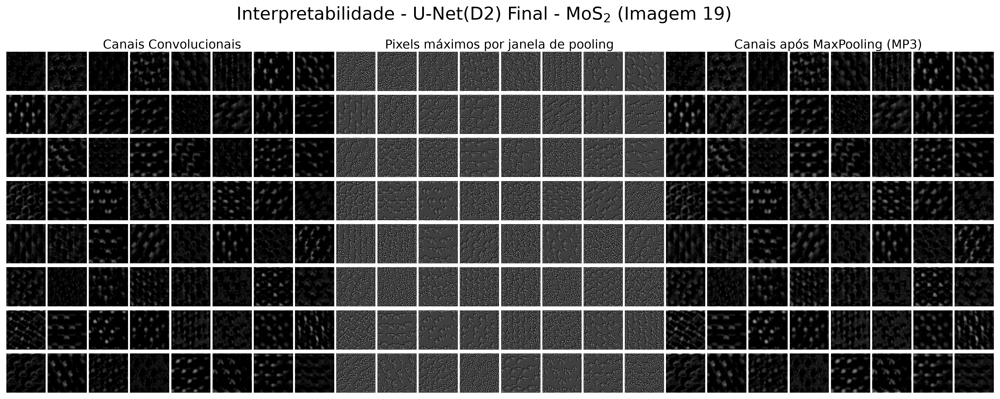

In [29]:
fig, axes = plt.subplots(8, 24, figsize=(20, 7))

for i in range(64):

    linha = i // 8
    coluna = i % 8

    # Convoluções
    axes[linha, coluna].imshow(
        imagens_conv3[0, i],
        cmap="gray",
        vmin=0,
        vmax=6
    )
    axes[linha, coluna].axis("off")

     # Pixel maximo
    axes[linha, coluna + 8].imshow(
        conjuntos3[j, i], cmap="gray", vmin=0, vmax=1
    )
    axes[linha, coluna + 8].axis("off")

    # MaxPooling
    axes[linha, coluna + 16].imshow(
        pool3_rsz[0, i],
        cmap="gray",
        vmin=0,
        vmax=6
    )
    axes[linha, coluna + 16].axis("off")

fig.suptitle(
    r"Interpretabilidade - U-Net(D2) Final - MoS$_2$ (Imagem 19)",
    fontsize=20
)

fig.text(
    0.255, 0.885,
    "Canais Convolucionais",
    ha="center",
    fontsize=14
)

fig.text(
    0.512, 0.885,
    "Pixels máximos por janela de pooling",
    ha="center",
    fontsize=14
)

fig.text(
    0.77, 0.885,
    "Canais após MaxPooling (MP3)",
    ha="center",
    fontsize=14
)

plt.subplots_adjust(
    wspace=0.05,
    hspace=0.05,
    top=0.88
)

plt.savefig(
    f"Imagens_interpretabilidade/{diretorio}/MP3_mos2_{diretorio}.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)